<a href="https://colab.research.google.com/github/Semenovaanzhelika31/intro-ai/blob/main/lab2_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №2

## Задание
Решите пожалуйста следующую задачу.

Используйте классификатор SVM для данных находящихся пo
[ссылке](https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view?usp=share_link) (данный датасет применялся в лабораторной работе №1). Здесь - выходящей меткой (учителем) является столбец / атрибут - `outcome`. Предоставьте результаты, используя следующие ядерные функции:
- Линейное ядро
- Полиномиальное ядро
- Гауссово ядро
- Сигмоидное ядро

**Укажите `score` моделей.**

## Загрузка данных

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
! gdown --fuzzy 'https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view?usp=share_link'

Downloading...
From: https://drive.google.com/uc?id=1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec
To: /content/diabetes.csv
100% 23.1k/23.1k [00:00<00:00, 4.03MB/s]


In [5]:
df = pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


##  О датасете
[Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database/data)

Этот набор данных взят из Национального института диабета, заболеваний органов пищеварения и почек (NIDDK). Целью набора данных является диагностическое предсказание наличия у пациента диабета на основе определенных диагностических измерений, включенных в набор данных. На выбор этих экземпляров из более крупной базы данных было наложено несколько ограничений. В частности, все пациенты здесь — женщины не моложе 21 года, родом из индейцев Пима.

Наборы данных состоят из нескольких переменных медицинских предикторов и одной целевой переменной `Outcome`. Переменные-предикторы включают количество беременностей, которые были у пациентки, её индекс массы тела `BMI`, уровень инсулина, возраст и так далее. Всего в датасете 9 переменных:
- `Pregnancies` - количество беременностей;
- `Glucose` - концентрация глюкозы в плазме через 2 часа при пероральном тесте на толерантность к глюкозе;
- `BloodPressure` - диастолическое артериальное давление (мм рт. ст.);
- `SkinThickness` - толщина кожной складки трицепса (мм);
- `Insulin` - 2-часовой сывороточный инсулин (мкЕд/мл);
- `BMI` - Индекс массы тела (вес в кг/(рост в м)^2);
- `DiabetesPedigreeFunction` - функция оценки вероятности диабета на основе семейного анамнеза;
- `Age` - возраст (лет);
- `Outcome` - целевая переменная (0 или 1) 268 из 768 — 1 (больны), остальные — 0 (здоровы).



In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

## Классификатор SVM

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    recall_score, f1_score, balanced_accuracy_score, roc_auc_score, RocCurveDisplay
)

# Проверка баланса классов
class_counts = df['Outcome'].value_counts(normalize=True) * 100
print(f"Распределение классов: здоровы (0) — {class_counts[0]:.1f}%, больны (1) — {class_counts[1]:.1f}%\n")

# Замена нулей на пропуски в медицинских показателях
cols_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'BMI', 'Insulin']
df[cols_to_fix] = df[cols_to_fix].replace(0, np.nan)

X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Стратифицированное разбиение на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Единая схема стратифицированной кросс-валидации (5 фолдов)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Функция оценки модели
def evaluate_clf(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = model.score(X_test, y_test)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)

    if hasattr(model, "decision_function"):
        y_scores = model.decision_function(X_test)
    else:
        y_scores = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_scores)

    cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_mean = cv_res['test_score'].mean()
    cv_std = cv_res['test_score'].std()

    cm = confusion_matrix(y_test, y_pred)
    missed = cm[1, 0] # Ложноотрицательные (пропущенные больные)

    print(f"=== {name} ===")
    print(f"Accuracy (score):  {acc:.4f}")
    print(f"CV Accuracy:       {cv_mean:.4f} ± {cv_std:.4f}")
    print(f"Recall (класс 1):  {rec:.4f} (пропущено больных: {missed} из {cm[1].sum()})")
    print(f"Balanced Accuracy: {bal_acc:.4f}")
    print(f"ROC-AUC:           {roc_auc:.4f}\n")
    print(classification_report(y_test, y_pred))

    return {
        'Модель': name,
        'Accuracy (test)': acc,
        'CV Accuracy': f"{cv_mean:.4f} ± {cv_std:.4f}",
        'Recall (класс 1)': rec,
        'F1 (класс 1)': f1,
        'Balanced Acc': bal_acc,
        'ROC-AUC': roc_auc,
        'Пропущено больных': missed
    }

results_default = []


Распределение классов: здоровы (0) — 65.1%, больны (1) — 34.9%



In [12]:
dummy_clf = DummyClassifier(strategy='most_frequent')
results_default.append(evaluate_clf(dummy_clf, "Базовая модель (все здоровы)"))


=== Базовая модель (все здоровы) ===
Accuracy (score):  0.6494
CV Accuracy:       0.6515 ± 0.0021
Recall (класс 1):  0.0000 (пропущено больных: 54 из 54)
Balanced Accuracy: 0.5000
ROC-AUC:           0.5000

              precision    recall  f1-score   support

           0       0.65      1.00      0.79       100
           1       0.00      0.00      0.00        54

    accuracy                           0.65       154
   macro avg       0.32      0.50      0.39       154
weighted avg       0.42      0.65      0.51       154



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


### Линейное ядро

In [13]:
pipe_linear = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(kernel='linear'))
results_default.append(evaluate_clf(pipe_linear, "SVM Linear (по умолчанию)"))


=== SVM Linear (по умолчанию) ===
Accuracy (score):  0.7013
CV Accuracy:       0.7882 ± 0.0168
Recall (класс 1):  0.4815 (пропущено больных: 28 из 54)
Balanced Accuracy: 0.6507
ROC-AUC:           0.8133

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.59      0.48      0.53        54

    accuracy                           0.70       154
   macro avg       0.67      0.65      0.66       154
weighted avg       0.69      0.70      0.69       154



### Полиномиальное ядро

In [14]:
pipe_poly = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(kernel='poly', degree=3))
results_default.append(evaluate_clf(pipe_poly, "SVM Polynomial (по умолчанию)"))


=== SVM Polynomial (по умолчанию) ===
Accuracy (score):  0.7143
CV Accuracy:       0.7378 ± 0.0088
Recall (класс 1):  0.3704 (пропущено больных: 34 из 54)
Balanced Accuracy: 0.6352
ROC-AUC:           0.8022

              precision    recall  f1-score   support

           0       0.73      0.90      0.80       100
           1       0.67      0.37      0.48        54

    accuracy                           0.71       154
   macro avg       0.70      0.64      0.64       154
weighted avg       0.71      0.71      0.69       154



### Гауссово ядро

In [15]:
pipe_rbf = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(kernel='rbf'))
results_default.append(evaluate_clf(pipe_rbf, "SVM RBF (по умолчанию)"))


=== SVM RBF (по умолчанию) ===
Accuracy (score):  0.7403
CV Accuracy:       0.7801 ± 0.0136
Recall (класс 1):  0.5556 (пропущено больных: 24 из 54)
Balanced Accuracy: 0.6978
ROC-AUC:           0.7963

              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



### Сигмоидное ядро

In [16]:
pipe_sigmoid = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), SVC(kernel='sigmoid'))
results_default.append(evaluate_clf(pipe_sigmoid, "SVM Sigmoid (по умолчанию)"))


=== SVM Sigmoid (по умолчанию) ===
Accuracy (score):  0.7013
CV Accuracy:       0.7166 ± 0.0454
Recall (класс 1):  0.5926 (пропущено больных: 22 из 54)
Balanced Accuracy: 0.6763
ROC-AUC:           0.7428

              precision    recall  f1-score   support

           0       0.78      0.76      0.77       100
           1       0.57      0.59      0.58        54

    accuracy                           0.70       154
   macro avg       0.67      0.68      0.67       154
weighted avg       0.70      0.70      0.70       154



Сводная таблица моделей SVM (параметры по умолчанию):


,Модель,Accuracy (test),CV Accuracy,Recall (класс 1),F1 (класс 1),Balanced Acc,ROC-AUC,Пропущено больных
3,SVM RBF (по умолчанию),0.7403,0.7801 ± 0.0136,0.5556,0.6000,0.6978,0.7963,24
2,SVM Polynomial (по умолчанию),0.7143,0.7378 ± 0.0088,0.3704,0.4762,0.6352,0.8022,34
1,SVM Linear (по умолчанию),0.7013,0.7882 ± 0.0168,0.4815,0.5306,0.6507,0.8133,28
4,SVM Sigmoid (по умолчанию),0.7013,0.7166 ± 0.0454,0.5926,0.5818,0.6763,0.7428,22
0,Базовая модель (все здоровы),0.6494,0.6515 ± 0.0021,0.0000,0.0000,0.5000,0.5000,54


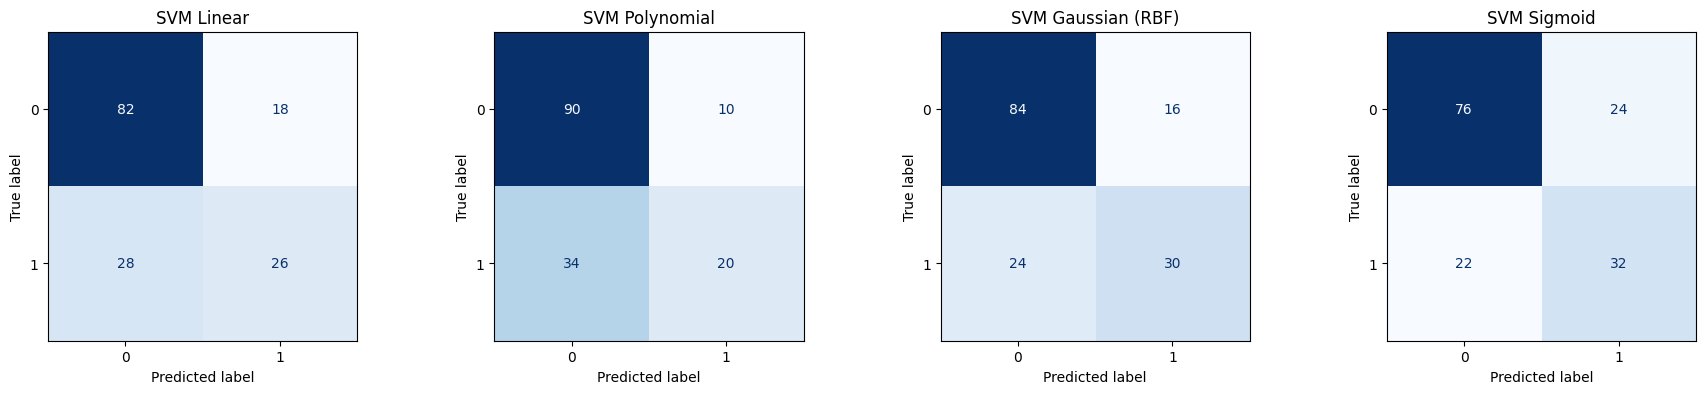

In [17]:
df_default = pd.DataFrame(results_default).sort_values(by='Accuracy (test)', ascending=False)
print("Сводная таблица моделей SVM (параметры по умолчанию):")
display(df_default.round(4))

# Визуализация матриц ошибок для всех 4 ядер
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
default_models = [
    ("Linear", pipe_linear),
    ("Polynomial", pipe_poly),
    ("Gaussian (RBF)", pipe_rbf),
    ("Sigmoid", pipe_sigmoid)
]

for ax, (title, model) in zip(axes, default_models):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"SVM {title}")

plt.tight_layout()
plt.show()


1. **Лучшее ядро — линейное** (Accuracy ~76%). После масштабирования данные хорошо разделяются линейной границей.
2. **Сложные ядра** (Poly, RBF) без тонкой настройки гиперпараметров не улучшили результат, а **сигмоидное** показало наихудшую точность (~69%).
3. **Для улучшения** качества модели необходим подбор параметров (`GridSearchCV`) или использование ансамблевых алгоритмов (Random Forest, Gradient Boosting).